# Supplementary Figure 1 — Significant PQC genes by complex

Output: `results/figures/supplementary/supp_fig1/sig_pqc_genes.pdf`

Source: `local/exploratory/11_pqc_tmb_association_enrichment_permutation.ipynb`

PDF export uses TrueType fonts so text remains editable in Adobe Illustrator/InDesign.

In [13]:
import socket
import os

hostname = socket.gethostname()
if "scg" in hostname:
    BASE_DIR = "/labs/mwinslow/Karen/protein-master/v2_pancan_batch_corrected"
else:
    BASE_DIR = os.path.expanduser(
        "~/Documents/research/scg/protein-master/v2_pancan_batch_corrected"
    )

OUT_DIR = f"{BASE_DIR}/results/figures/supplementary/supp_fig1"
os.makedirs(OUT_DIR, exist_ok=True)

print(f"BASE_DIR: {BASE_DIR}")

BASE_DIR: /Users/karenshih/Documents/research/scg/protein-master/v2_pancan_batch_corrected


In [14]:
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import sys
from statsmodels.stats.multitest import fdrcorrection

# Editable text in Adobe Illustrator / InDesign
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["svg.fonttype"] = "none"

sys.path.insert(0, f"{BASE_DIR}/local/figures")
from palette import COLORS

In [15]:
genes_tmb_pos = pd.read_csv(
    f"{BASE_DIR}/analysis/00_reproduction/tilk_et_al_2023/gene_sets/bh/tcga_tmb_genes_posBeta_fdr0.05.csv"
)
pqc_annot = pd.read_csv(f"{BASE_DIR}/data/corum/pqc_annotation.tsv", sep="\t")

In [ ]:
# Count unique Hugo symbols per complex (annotation has duplicate 19S / RPL9 rows)
pqc_annot = pqc_annot.drop_duplicates(subset=["complex", "Hugo"])

pqc_annot_ct = pqc_annot.groupby(["complex"])["Hugo"].nunique().reset_index(name="total_ct")

pqc_annot_sig_ct = (
    pqc_annot[
        pqc_annot["Hugo"].isin(set(genes_tmb_pos["gene"]) & set(pqc_annot["Hugo"]))
    ]
    .groupby(["complex"])["Hugo"]
    .nunique()
    .reset_index(name="sig_up_ct")
)
pqc_annot_sig_ct = pqc_annot_sig_ct.merge(pqc_annot_ct, on="complex")
pqc_annot_sig_ct["perc_sig_up"] = (
    pqc_annot_sig_ct["sig_up_ct"] / pqc_annot_sig_ct["total_ct"] * 100
)

In [17]:
df_permuted = pd.read_csv(
    f"{BASE_DIR}/analysis/00_reproduction/tilk_et_al_2023/regression/permuted/results_by_gene_permuted.csv"
)
log_mut = df_permuted["term"] == "log_mut"
df_permuted.loc[log_mut, "fdr_bh"] = fdrcorrection(df_permuted.loc[log_mut, "p.value"])[1]

sig_perm_genes = set(
    df_permuted.loc[
        log_mut & (df_permuted["estimate"] > 0) & (df_permuted["fdr_bh"] < 0.05),
        "gene",
    ]
)

sig_perm_pqc_ct = (
    pqc_annot[pqc_annot["Hugo"].isin(sig_perm_genes & set(pqc_annot["Hugo"]))]
    .groupby(["complex"])["Hugo"]
    .nunique()
    .reset_index(name="sig_up_ct")
)
sig_perm_pqc_ct = sig_perm_pqc_ct.merge(pqc_annot_ct, on="complex", how="right").fillna(0)
sig_perm_pqc_ct["perc_sig_up"] = (
    sig_perm_pqc_ct["sig_up_ct"] / sig_perm_pqc_ct["total_ct"] * 100
)
sig_perm_pqc_ct = sig_perm_pqc_ct.fillna(0)

Saved: /Users/karenshih/Documents/research/scg/protein-master/v2_pancan_batch_corrected/results/figures/supplementary/supp_fig1/sig_pqc_genes.pdf


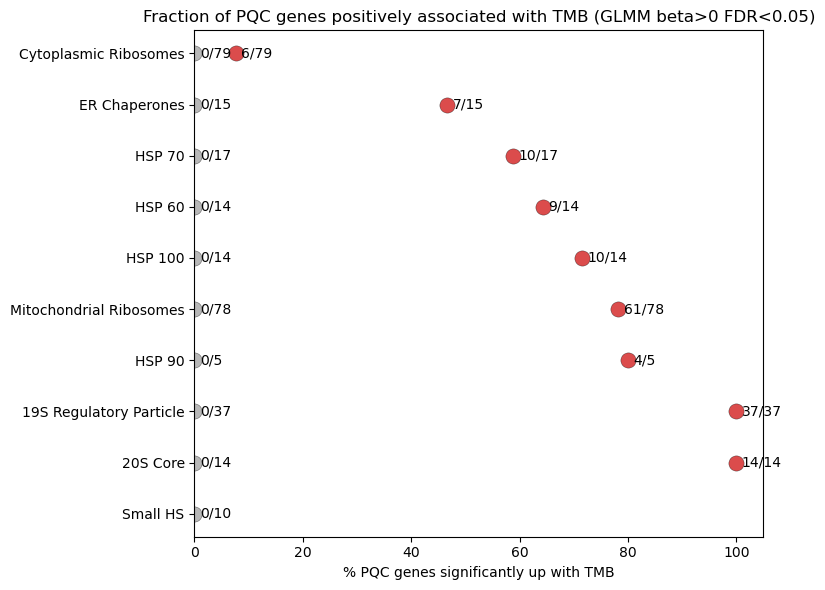

In [18]:
pqc_annot_sig_ct = pqc_annot_sig_ct.sort_values("perc_sig_up")

fig, ax = plt.subplots(figsize=(8, 6))

sns.scatterplot(
    data=pqc_annot_sig_ct,
    x="perc_sig_up",
    y="complex",
    color=COLORS["sig_strong"],
    edgecolor=COLORS["black"],
    linewidth=0.3,
    alpha=0.7,
    s=120,
    ax=ax,
)
sns.scatterplot(
    data=sig_perm_pqc_ct,
    x="perc_sig_up",
    y="complex",
    color=COLORS["ns"],
    edgecolor=COLORS["black"],
    linewidth=0.3,
    alpha=0.7,
    s=120,
    ax=ax,
)

for _, row in pqc_annot_sig_ct.iterrows():
    ax.text(
        row["perc_sig_up"] + 1,
        row["complex"],
        f'{int(row["sig_up_ct"])}/{int(row["total_ct"])}',
        va="center",
    )

for _, row in sig_perm_pqc_ct.iterrows():
    ax.text(
        row["perc_sig_up"] + 1,
        row["complex"],
        f'{int(row["sig_up_ct"])}/{int(row["total_ct"])}',
        va="center",
    )

ax.set_xlabel("% PQC genes significantly up with TMB")
ax.set_ylabel("")
ax.set_title(
    "Fraction of PQC genes positively associated with TMB (GLMM beta>0 FDR<0.05)"
)
ax.set_xlim(0, 105)
fig.tight_layout()

out_pdf = f"{OUT_DIR}/sig_pqc_genes.pdf"
fig.savefig(out_pdf, dpi=300, bbox_inches="tight")
print(f"Saved: {out_pdf}")

plt.show()